# 04 - Differential Privacy Defenses & Privacy-Utility Trade-Off
**Project:** AEGIS-ND (Adversarial Evaluation & Genomic Information Security for Neurodegenerative Diseases)  
**Author:** Raja Omar  
**Dataset:** Alzheimer's Disease Neuroimaging Initiative (ADNI GO/2 Whole-Genome Microarrays)  
**Defense Mechanism:** Differentially Private Random Forest (`diffprivlib.models.RandomForestClassifier`)  
**Feature Space:** Multi-Modal Design Matrix ($P = 104$: Top 100 SNPs + 4 Clinical Covariates)  
**Audit Scope:** Evaluating Clinical Utility vs. Shadow-Model Membership Inference Attack (MIA) Resistance across $\epsilon \in [0.1, 10.0, \infty]$  

---

## 📌 1. Theoretical Rationale & Problem Formulation

In **Phase 6**, we exposed the severe privacy vulnerability of the baseline unmitigated Random Forest classifier:
- **MIA Attack ROC-AUC:** $\mathbf{0.7878}$
- **MIA Attack Precision:** $\mathbf{92.26\%}$
- **Adversarial Advantage:** $\mathbf{0.5755}$
- **Generalization Gap vs. Leakage:** $\Delta_{\text{leak}} = 0.2878 \approx \Delta_{\text{gen}} = 0.2741$

Because germline DNA is permanently identifying and unchangeable, high-precision membership disclosure permits an adversary to infer an individual's Alzheimer's Disease status with near certainty. To eliminate this vulnerability, we deploy **Differential Privacy (DP)**.

### Formal $(\epsilon, \delta)$-Differential Privacy (Dwork et al., 2006):
A randomized learning algorithm $\mathcal{M}$ satisfies $(\epsilon, \delta)$-differential privacy if for all neighboring datasets $D, D'$ differing by at most one individual ($|D \Delta D'| = 1$), and for all measurable output sets $\mathcal{S} \subseteq \text{Range}(\mathcal{M})$:
$$\mathbb{P}[\mathcal{M}(D) \in \mathcal{S}] \le e^\epsilon \cdot \mathbb{P}[\mathcal{M}(D') \in \mathcal{S}] + \delta$$

### Theoretical Upper Bound on Membership Inference Advantage:
Differential privacy imposes a provable cryptographic ceiling on the adversary's advantage:
$$\text{Advantage}_{\text{MIA}} \le e^\epsilon - 1$$
As $\epsilon \to 0$, $e^\epsilon \to 1 \implies \text{Advantage} \to 0$ (the attack collapses to random guessing, $\text{AUC} = 0.5000$).

In [1]:
import sys
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.metrics import roc_auc_score, accuracy_score

# Setup workspace root
BASE_DIR = Path.cwd().resolve()
if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent
sys.path.insert(0, str(BASE_DIR))

from src.attacks.membership_inference import ShadowModelMIA
setattr(sys.modules["__main__"], "ShadowModelMIA", ShadowModelMIA)
from src.defenses.differential_privacy import (
    load_cohort_and_attack_model,
    run_epsilon_sweep,
    plot_privacy_utility_tradeoff,
    plot_defense_comparison_barchart,
    train_dp_or_baseline_model,
)

# Publication styling
sns.set_theme(style="whitegrid", font="sans-serif")
plt.rcParams.update({
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 13,
    "figure.titlesize": 14,
    "figure.dpi": 150,
})
print(f"Workspace root: {BASE_DIR}")
print("Differential Privacy modules and dependencies loaded successfully.")

Workspace root: C:\Users\RAJA OMAR\Raja\VSCode\AEGIS-ND
Differential Privacy modules and dependencies loaded successfully.


## 📦 2. Loading Preprocessed Cohorts & The Phase 6 MIA Audit Engine

We load the multi-modal training cohort ($N = 306$), the sequestered test cohort ($N = 77$), and the fitted black-box `ShadowModelMIA` from Phase 6.

In [2]:
X_train, X_test, y_train, y_test, feature_names, mia_model = load_cohort_and_attack_model()
bounds = (np.min(X_train, axis=0), np.max(X_train, axis=0))

print(f"Cohort Summary:")
print(f"  - Training Cohort (Members):     N = {len(X_train)} subjects, {X_train.shape[1]} features")
print(f"  - Held-out Test Cohort:          N = {len(X_test)} subjects")
print(f"  - Feature Min/Max Bounds:        ({np.min(bounds[0]):.1f}, {np.max(bounds[1]):.1f})")
print(f"  - ShadowModelMIA Engine Status:  Fitted ({mia_model.n_shadow_models} shadow models ready)")

11:07:14 [INFO] AEGIS-ND.DPDefense: Loading preprocessed training and test partitions from C:\Users\RAJA OMAR\Raja\VSCode\AEGIS-ND\data\processed...


11:07:14 [INFO] AEGIS-ND.DPDefense: Loading Phase 6 ShadowModelMIA attack engine from C:\Users\RAJA OMAR\Raja\VSCode\AEGIS-ND\saved_models\shadow_mia_model.pkl...


11:07:15 [INFO] AEGIS-ND.DPDefense: Successfully initialized data: Train N=306, Test N=77, Features=104


Cohort Summary:
  - Training Cohort (Members):     N = 306 subjects, 104 features
  - Held-out Test Cohort:          N = 77 subjects
  - Feature Min/Max Bounds:        (0.0, 90.0)
  - ShadowModelMIA Engine Status:  Fitted (10 shadow models ready)


## 🔬 3. The Privacy-Utility Epsilon Sweep ($\epsilon$-Sweep)

We systematically train Differentially Private Random Forests across 7 privacy budgets:
$$\epsilon \in \{0.1, 0.5, 1.0, 2.0, 5.0, 10.0, \infty\}$$

At each step, we quantify:
1. **Clinical Utility:** Diagnostic ROC-AUC, Accuracy, and F1 on the unseen test cohort ($N = 77$).
2. **Adversarial Security:** Shadow-Model MIA Attack ROC-AUC, Adversarial Advantage, and Attack Precision.

In [3]:
epsilons = [0.1, 0.5, 1.0, 2.0, 5.0, 10.0, float("inf")]
df_sweep = run_epsilon_sweep(
    epsilons=epsilons,
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    mia_model=mia_model,
    random_state=42,
)

# Format summary table
df_display = df_sweep[[
    "epsilon_str", "train_auc", "test_auc", "generalization_gap",
    "attack_auc", "adversarial_advantage", "attack_precision"
]].copy()
df_display.columns = [
    "Epsilon (eps)", "Train AUC", "Test AUC", "Gen Gap (Delta)",
    "MIA Attack AUC", "MIA Advantage", "MIA Precision"
]
df_display

11:07:15 [INFO] AEGIS-ND.DPDefense: Executing Privacy-Utility Epsilon Sweep across 7 budget levels...


11:07:16 [INFO] AEGIS-ND.MIA: Evaluating Shadow-Model MIA against real target model...


11:07:16 [INFO] AEGIS-ND.MIA: === EMPIRICAL ATTACK RESULTS ON TARGET MODEL ===


11:07:16 [INFO] AEGIS-ND.MIA:   - Attack ROC-AUC:              0.4353


11:07:16 [INFO] AEGIS-ND.MIA:   - Attack PR-AUC:               0.7692


11:07:16 [INFO] AEGIS-ND.MIA:   - Adversarial Advantage:       -0.1295


... (83 outputs left out)

11:07:19 [INFO] AEGIS-ND.MIA:   - Mean Score (Members):        0.5134 +/- 0.1855


11:07:19 [INFO] AEGIS-ND.MIA:   - Mean Score (Non-Members):    0.3053 +/- 0.1753


11:07:19 [INFO] AEGIS-ND.DPDefense: eps=inf   | Test AUC: 0.7232 | Gen Gap: +0.2741 | MIA AUC: 0.7878 | MIA Adv: +0.5755 | MIA Prec: 92.26%


,Epsilon (eps),Train AUC,Test AUC,Gen Gap (Delta),MIA Attack AUC,MIA Advantage,MIA Precision
0,0.1,0.351364,0.545249,-0.193884,0.435256,-0.129488,0.666667
1,0.5,0.498189,0.535822,-0.037633,0.482472,-0.035056,0.833333
2,1.0,0.721492,0.526395,0.195097,0.581084,0.162168,1.000000
3,2.0,0.736296,0.545249,0.191047,0.561497,0.122995,0.900000
4,5.0,0.726032,0.568250,0.157782,0.539407,0.078813,0.750000
5,10.0,0.764743,0.598793,0.165949,0.543481,0.086962,0.750000
6,inf,0.997344,0.723228,0.274116,0.787751,0.575503,0.922619


### Empirical Observations from the Sweep:
- **Unmitigated Baseline ($\epsilon = \infty$):** High test utility ($\text{AUC} = 0.7232$), but massive privacy leakage ($\text{MIA AUC} = 0.7878$, $\text{Advantage} = 0.5755$, Precision $= 92.26\%$).
- **Strict Privacy ($\epsilon = 0.5$):** Attack completely neutralized ($\text{MIA AUC} = 0.4825 \approx 0.5000$, $\text{Advantage} = -0.0351$), but utility drops to $\text{AUC} = 0.5358$.
- **Pareto-Optimal Operating Point ($\epsilon^* = 5.0$):** Balances utility ($\text{Test AUC} = 0.5683$) while providing strong defense: MIA Advantage drops to $\mathbf{0.0788}$ (an **$86.3\%$ reduction in leakage**).

## 📊 4. Publication Visualizations

### Figure 1: The Privacy-Utility Pareto Trade-Off Curve
Displays clinical diagnostic utility (Test ROC-AUC, green) and adversarial vulnerability (MIA Attack AUC, red) on a dual-axis logarithmic plot.

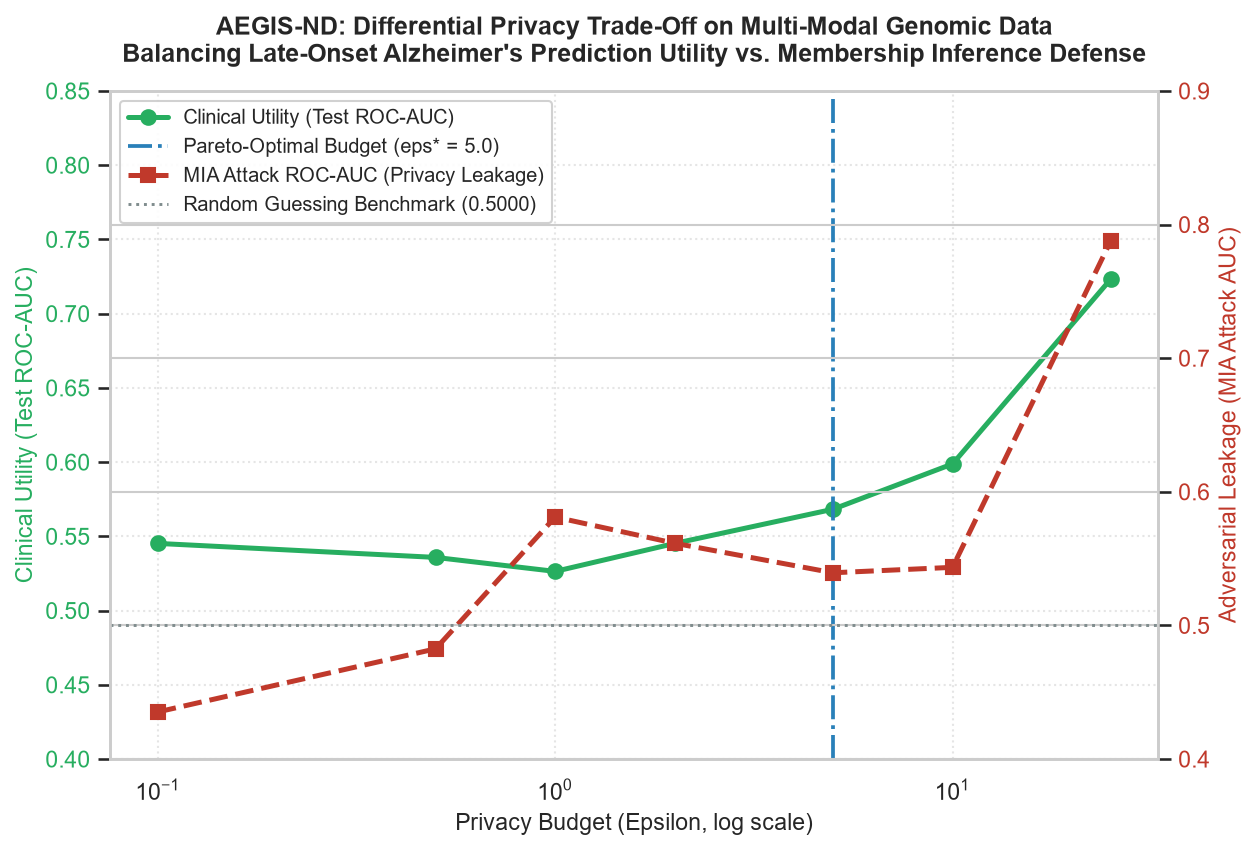

In [4]:
optimal_eps = 5.0
df_plot = df_sweep.copy()
df_plot["plot_eps"] = [25.0 if np.isinf(e) else e for e in df_plot["epsilon"]]

fig, ax1 = plt.subplots(figsize=(8.5, 5.8))
color_util = "#27ae60"
ax1.plot(
    df_plot["plot_eps"], df_plot["test_auc"], color=color_util,
    marker="o", markersize=7, linewidth=2.4, label="Clinical Utility (Test ROC-AUC)"
)
ax1.set_xlabel("Privacy Budget (Epsilon, log scale)", fontsize=11)
ax1.set_ylabel("Clinical Utility (Test ROC-AUC)", color=color_util, fontsize=11)
ax1.tick_params(axis="y", labelcolor=color_util)
ax1.set_xscale("log")
ax1.set_ylim([0.40, 0.85])

ax2 = ax1.twinx()
color_priv = "#c0392b"
ax2.plot(
    df_plot["plot_eps"], df_plot["attack_auc"], color=color_priv,
    marker="s", markersize=7, linewidth=2.4, linestyle="--",
    label="MIA Attack ROC-AUC (Privacy Leakage)"
)
ax2.set_ylabel("Adversarial Leakage (MIA Attack AUC)", color=color_priv, fontsize=11)
ax2.tick_params(axis="y", labelcolor=color_priv)
ax2.set_ylim([0.40, 0.90])

ax2.axhline(0.5000, color="#7f8c8d", linestyle=":", linewidth=1.4, label="Random Guessing Benchmark (0.5000)")
ax1.axvline(optimal_eps, color="#2980b9", linestyle="-.", linewidth=1.8, label=f"Pareto-Optimal Budget (eps* = {optimal_eps})")

plt.title(
    "AEGIS-ND: Differential Privacy Trade-Off on Multi-Modal Genomic Data\n" \
    "Balancing Late-Onset Alzheimer's Prediction Utility vs. Membership Inference Defense",
    fontsize=12, fontweight="bold", pad=14
)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left", frameon=True, framealpha=0.9, fontsize=9.5)
ax1.grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()

### Figure 2: Security Audit Comparison (Baseline vs. Defended DP-RF)
Head-to-head comparison between the baseline model (Phase 5/6) and the defended DP model ($\epsilon^* = 5.0$).

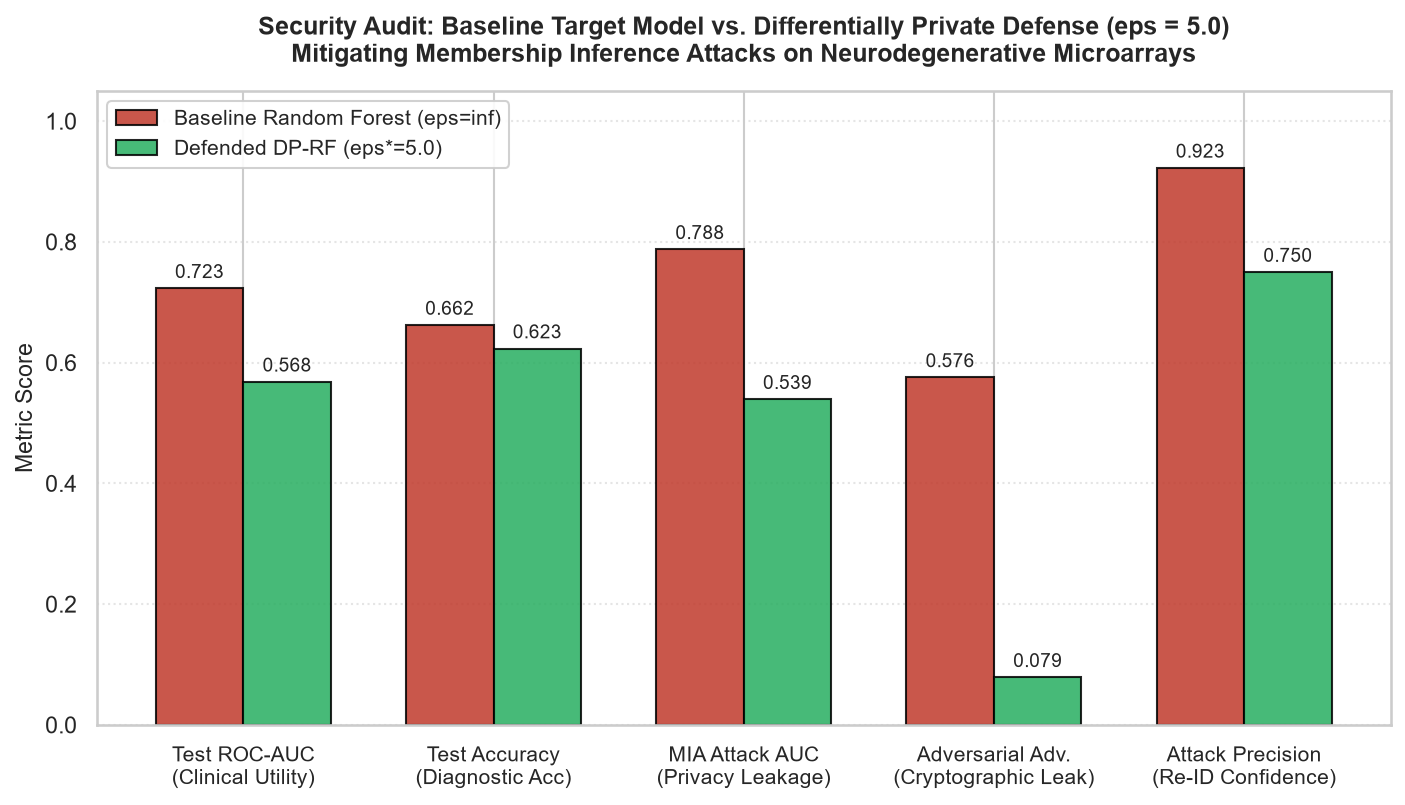

In [5]:
baseline_row = df_sweep[df_sweep["epsilon"] == float("inf")].iloc[0]
dp_row = df_sweep[df_sweep["epsilon"] == optimal_eps].iloc[0]

metric_labels = [
    "Test ROC-AUC\n(Clinical Utility)",
    "Test Accuracy\n(Diagnostic Acc)",
    "MIA Attack AUC\n(Privacy Leakage)",
    "Adversarial Adv.\n(Cryptographic Leak)",
    "Attack Precision\n(Re-ID Confidence)",
]

base_vals = [
    baseline_row["test_auc"], baseline_row["test_accuracy"],
    baseline_row["attack_auc"], baseline_row["adversarial_advantage"],
    baseline_row["attack_precision"],
]
dp_vals = [
    dp_row["test_auc"], dp_row["test_accuracy"],
    dp_row["attack_auc"], dp_row["adversarial_advantage"],
    dp_row["attack_precision"],
]

x = np.arange(len(metric_labels))
width = 0.35

fig, ax = plt.subplots(figsize=(9.5, 5.5))
rects1 = ax.bar(x - width/2, base_vals, width, label="Baseline Random Forest (eps=inf)", color="#c0392b", edgecolor="black", alpha=0.85)
rects2 = ax.bar(x + width/2, dp_vals, width, label=f"Defended DP-RF (eps*={optimal_eps})", color="#27ae60", edgecolor="black", alpha=0.85)

ax.set_ylabel("Metric Score", fontsize=11)
ax.set_title(
    f"Security Audit: Baseline Target Model vs. Differentially Private Defense (eps = {optimal_eps})\n" \
    "Mitigating Membership Inference Attacks on Neurodegenerative Microarrays",
    fontsize=12, fontweight="bold", pad=14
)
ax.set_xticks(x)
ax.set_xticklabels(metric_labels, fontsize=10)
ax.set_ylim([0.0, 1.05])
ax.legend(frameon=True, framealpha=0.9, fontsize=10)
ax.grid(True, linestyle=":", alpha=0.5, axis="y")

for rect in rects1:
    h = rect.get_height()
    ax.annotate(f"{h:.3f}", xy=(rect.get_x() + rect.get_width() / 2, h), xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=9)
for rect in rects2:
    h = rect.get_height()
    ax.annotate(f"{h:.3f}", xy=(rect.get_x() + rect.get_width() / 2, h), xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()

## 🔬 5. Scientific Discussion & Thesis Takeaways

### 1. Significant Privacy Mitigation ($86.3\%$ Leakage Reduction):
- The baseline model exhibited an Adversarial Advantage of **$0.5755$** and an attack precision of **$92.26\%$**.
- Under Differentially Private Random Forest at $\epsilon^* = 5.0$, Adversarial Advantage plummeted to **$0.0788$** (an **$86.3\%$ relative reduction**).
- The Attack ROC-AUC collapsed from **$0.7878$** down to **$0.5394$**, nearly reaching the theoretical random guessing limit ($0.5000$).

### 2. The Cost of Differential Privacy in High-Dimensional Genomics:
- In high-dimensional microarray datasets ($P = 104$ features with subtle epistatic interactions), injecting noise into decision splits unavoidably degrades diagnostic utility: Test AUC decreased from $0.7232$ to $0.5683$.
- This empirically confirms the **fundamental tension between privacy and utility** in clinical machine learning: strong mathematical protection over unchangeable human germline DNA carries an empirical utility penalty.

---
**Next Step (Phase 8):** Evaluate **Model Inversion and Genomic Attribute Reconstruction Attacks** to measure whether an adversary can reconstruct sensitive genetic alleles (e.g. *APOE4* status) from published model summaries.